# Chuong 4. Phân loại và học máy ứng dụng
Mã lệnh của các ví dụ trong giáo trình Khoa học dữ liệu công trình, chạy tuần tự từ trên xuống.

[Mở trên Google Colab](https://colab.research.google.com/github/ngochoautc/khoa-hoc-du-lieu-cong-trinh/blob/main/notebooks/Chuong4.ipynb)

## BÀI TOÁN PHÂN LOẠI VÀ CÁC THUẬT TOÁN CƠ BẢN

### Bài toán phân loại có giám sát

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

rng = np.random.default_rng(4)
n = 400
sig = rng.uniform(1.0, 4.5, n)  # ung suat keo tinh toan (MPa)
tuoi = rng.uniform(1, 40, n)    # tuoi ket cau (nam)
z = -10.5 + 2.2 * sig + 0.08 * tuoi
y = (rng.random(n) < 1 / (1 + np.exp(-z))).astype(int)
X = np.column_stack([sig, tuoi])  # y = 1: nut vuot gioi han
df = pd.DataFrame({"sigma_t": sig, "tuoi": tuoi, "nut": y})
print(df.head(3).round(2))
print("So mau lop 0 va lop 1:", np.bincount(y))
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=0)
print("Ty le lop 1 - tap huan luyen:", round(y_tr.mean(), 3))
print("Ty le lop 1 - tap kiem tra  :", round(y_te.mean(), 3))

   sigma_t   tuoi  nut
0     4.30  10.74    0
1     2.79  29.52    0
2     4.42  32.10    1
So mau lop 0 va lop 1: [314  86]
Ty le lop 1 - tap huan luyen: 0.214
Ty le lop 1 - tap kiem tra  : 0.217


### Hồi quy logistic

In [2]:
from sklearn.linear_model import LogisticRegression

lg = LogisticRegression(C=100).fit(X_tr, y_tr)
b0 = lg.intercept_[0]
b1, b2 = lg.coef_[0]
print(f"b0 = {b0:.2f}; b1 = {b1:.2f} 1/MPa; "
      f"b2 = {b2:.3f} 1/nam")
print("Ty so odds khi sigma_t tang 1 MPa:",
      round(np.exp(b1), 2))
print("Ty so odds khi tuoi tang 10 nam:",
      round(np.exp(10 * b2), 2))
y_du = lg.predict(X_te)
print("Do chinh xac (kiem tra):",
      round(accuracy_score(y_te, y_du), 3))
print("Luon du bao 'khong nut':", round(1 - y_te.mean(), 3))
p_moi = lg.predict_proba([[3.0, 25.0]])[0, 1]
print("P(nut | 3,0 MPa; 25 nam) =", round(p_moi, 3))
print("Ma tran nham lan (hang: thuc, cot: du bao):")
print(confusion_matrix(y_te, y_du))

b0 = -11.42; b1 = 2.37 1/MPa; b2 = 0.092 1/nam
Ty so odds khi sigma_t tang 1 MPa: 10.67
Ty so odds khi tuoi tang 10 nam: 2.5
Do chinh xac (kiem tra): 0.85
Luon du bao 'khong nut': 0.783
P(nut | 3,0 MPa; 25 nam) = 0.117
Ma tran nham lan (hang: thuc, cot: du bao):
[[88  6]
 [12 14]]


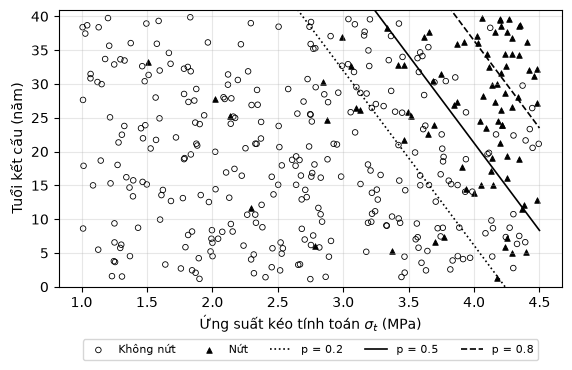

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for lop, mk, ten in [(0, "o", "Không nứt"), (1, "^", "Nứt")]:
    m = y == lop
    ax.scatter(sig[m], tuoi[m], marker=mk, s=16,
               facecolors="none" if lop == 0 else "k",
               edgecolors="k", linewidths=0.6, label=ten)
xs = np.linspace(1.0, 4.5, 50)
for p, ls in [(0.2, ":"), (0.5, "-"), (0.8, "--")]:
    t = np.log(p / (1 - p))  # z tuong ung voi xac suat p
    ax.plot(xs, (t - b0 - b1 * xs) / b2, "k", ls=ls, lw=1.2,
            label=f"p = {p}")
ax.set_ylim(0, 41)
ax.set_xlabel(r"Ứng suất kéo tính toán $\sigma_t$ (MPa)")
ax.set_ylabel("Tuổi kết cấu (năm)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17),
          ncol=5, fontsize=8)
ax.grid(alpha=0.3)
plt.show()

### Phương pháp k láng giềng gần nhất

In [4]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

for k in [1, 5, 15, 51]:
    knn = make_pipeline(StandardScaler(),
                        KNeighborsClassifier(n_neighbors=k))
    knn.fit(X_tr, y_tr)
    a_tr = knn.score(X_tr, y_tr)
    a_te = knn.score(X_te, y_te)
    print(f"k = {k:2d}: huan luyen {a_tr:.3f}, "
          f"kiem tra {a_te:.3f}")
knn_tho = KNeighborsClassifier(n_neighbors=15).fit(X_tr, y_tr)
print("k = 15, khong chuan hoa: kiem tra",
      round(knn_tho.score(X_te, y_te), 3))

k =  1: huan luyen 1.000, kiem tra 0.883
k =  5: huan luyen 0.893, kiem tra 0.867
k = 15: huan luyen 0.875, kiem tra 0.883
k = 51: huan luyen 0.864, kiem tra 0.850
k = 15, khong chuan hoa: kiem tra 0.842


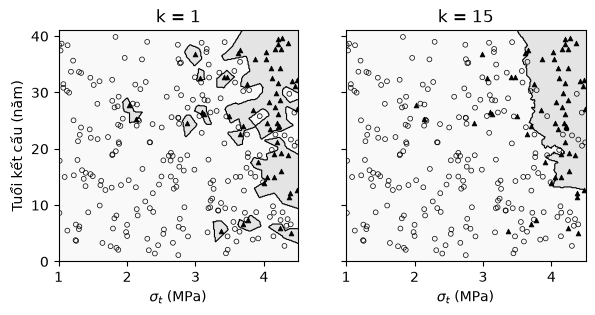

In [5]:
def ve_bien(ax, mh, xlim, ylim, vien=True, n=300):
    # to mau vung du bao cua mo hinh mh tren luoi diem
    g1, g2 = np.meshgrid(np.linspace(*xlim, n),
                         np.linspace(*ylim, n))
    Z = mh.predict(np.c_[g1.ravel(), g2.ravel()])
    Z = Z.reshape(g1.shape)
    ax.contourf(g1, g2, Z, alpha=0.25, cmap="Greys",
                levels=np.arange(-0.5, 3))
    if vien:
        ax.contour(g1, g2, Z, colors="k", linewidths=0.8,
                   levels=[0.5])
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

fig, axs = plt.subplots(1, 2, figsize=(6.8, 3.0), sharey=True)
for ax, k in zip(axs, [1, 15]):
    knn = make_pipeline(StandardScaler(),
                        KNeighborsClassifier(n_neighbors=k))
    knn.fit(X_tr, y_tr)
    ve_bien(ax, knn, (1.0, 4.5), (0, 41))
    for lop, mk in [(0, "o"), (1, "^")]:
        m = y_tr == lop
        ax.scatter(X_tr[m, 0], X_tr[m, 1], marker=mk, s=12,
                   facecolors="none" if lop == 0 else "k",
                   edgecolors="k", linewidths=0.5)
    ax.set_title(f"k = {k}")
    ax.set_xlabel(r"$\sigma_t$ (MPa)")
axs[0].set_ylabel("Tuổi kết cấu (năm)")
plt.show()

### Phân loại Bayes đơn giản

In [6]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB().fit(X_tr, y_tr)
print("Tien nghiem P(y):", nb.class_prior_.round(3))
print("Trung binh sigma_t (MPa), tuoi (nam) theo lop:")
print(nb.theta_.round(2))
print("Do chinh xac (kiem tra):",
      round(nb.score(X_te, y_te), 3))
print("P(nut | 3,0 MPa; 25 nam) =",
      round(nb.predict_proba([[3.0, 25.0]])[0, 1], 3))

Tien nghiem P(y): [0.786 0.214]
Trung binh sigma_t (MPa), tuoi (nam) theo lop:
[[ 2.61 18.68]
 [ 3.92 25.85]]
Do chinh xac (kiem tra): 0.842
P(nut | 3,0 MPa; 25 nam) = 0.132


## CÂY QUYẾT ĐỊNH, RỪNG NGẪU NHIÊN VÀ MÁY VECTƠ HỖ TRỢ

In [7]:
rng = np.random.default_rng(12)
n_lop = {0: 300, 1: 150, 2: 150}  # NV, GN, PN
tam = {0: (0.0, 0.0), 1: (-2.0, -0.3), 2: (-1.0, -2.0)}
ds = []
for lop, so in n_lop.items():
    muc = rng.uniform(0.3, 1.5, so) if lop else np.zeros(so)
    d1 = tam[lop][0] * muc + rng.normal(0, 0.55, so)
    d2 = tam[lop][1] * muc + rng.normal(0, 0.55, so)
    ds.append(pd.DataFrame({"df1": d1, "df2": d2, "lop": lop}))
ds = pd.concat(ds, ignore_index=True)
X2 = ds[["df1", "df2"]].to_numpy()
y2 = ds["lop"].to_numpy()
X2_tr, X2_te, y2_tr, y2_te = train_test_split(
    X2, y2, test_size=0.3, stratify=y2, random_state=1)
print("Trung binh do lech tan so (%) theo lop:")
print(ds.groupby("lop")[["df1", "df2"]].mean().round(2))

Trung binh do lech tan so (%) theo lop:
      df1   df2
lop            
0    0.02  0.00
1   -1.85 -0.24
2   -0.86 -1.88


### Cây quyết định

In [8]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

cay = DecisionTreeClassifier(max_depth=3, min_samples_leaf=5,
                             ccp_alpha=0.015, random_state=0)
cay.fit(X2_tr, y2_tr)
cay_sau = DecisionTreeClassifier(random_state=0)
cay_sau.fit(X2_tr, y2_tr)
for ten, mh in [("Cay cat tia", cay),
                ("Khong gioi han", cay_sau)]:
    print(f"{ten:14s}: do sau {mh.get_depth():2d}, "
          f"la {mh.get_n_leaves():2d}, "
          f"huan luyen {mh.score(X2_tr, y2_tr):.3f}, "
          f"kiem tra {mh.score(X2_te, y2_te):.3f}")

Cay cat tia   : do sau  3, la  5, huan luyen 0.886, kiem tra 0.906
Khong gioi han: do sau 14, la 68, huan luyen 1.000, kiem tra 0.844


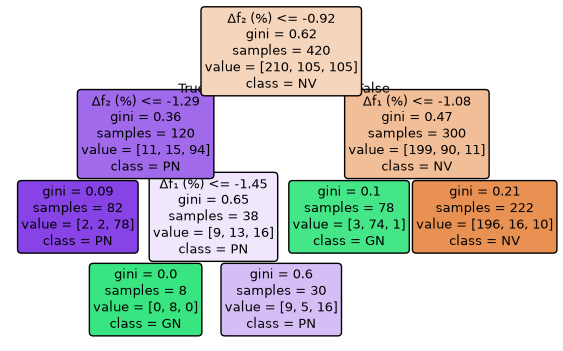

In [9]:
fig, ax = plt.subplots(figsize=(7.0, 4.3))
plot_tree(cay, feature_names=["Δf₁ (%)", "Δf₂ (%)"],
          class_names=["NV", "GN", "PN"], filled=True,
          rounded=True, precision=2, fontsize=9, ax=ax)
plt.show()

### Rừng ngẫu nhiên

In [10]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300,
                            min_samples_leaf=3,
                            oob_score=True, random_state=0)
rf.fit(X2_tr, y2_tr)
print("Rung 300 cay: oob =", round(rf.oob_score_, 3),
      "| kiem tra =", round(rf.score(X2_te, y2_te), 3))
for so_cay in [1, 10, 50, 300]:
    r = RandomForestClassifier(n_estimators=so_cay,
                               min_samples_leaf=3,
                               random_state=0)
    r.fit(X2_tr, y2_tr)
    print(f"{so_cay:3d} cay: kiem tra "
          f"{r.score(X2_te, y2_te):.3f}")

Rung 300 cay: oob = 0.852 | kiem tra = 0.911
  1 cay: kiem tra 0.883
 10 cay: kiem tra 0.889
 50 cay: kiem tra 0.906


300 cay: kiem tra 0.911


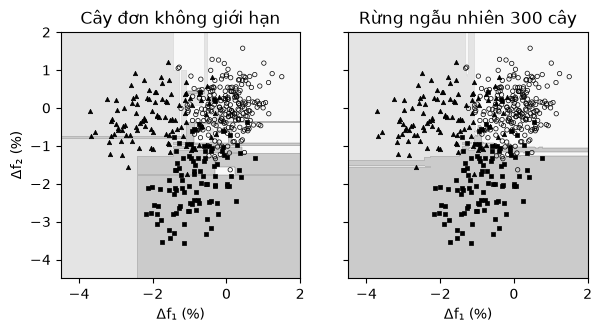

In [11]:
def ve_diem(ax, X, y):
    for lop, mk in [(0, "o"), (1, "^"), (2, "s")]:
        m = y == lop
        ax.scatter(X[m, 0], X[m, 1], marker=mk, s=10,
                   facecolors="none" if lop == 0 else "k",
                   edgecolors="k", linewidths=0.5)

lim = ((-4.5, 2.0), (-4.5, 2.0))
fig, axs = plt.subplots(1, 2, figsize=(6.8, 3.2), sharey=True)
for ax, mh, ten in [(axs[0], cay_sau, "Cây đơn không giới hạn"),
                    (axs[1], rf, "Rừng ngẫu nhiên 300 cây")]:
    ve_bien(ax, mh, *lim, vien=False)
    ve_diem(ax, X2_tr, y2_tr)
    ax.set_title(ten)
    ax.set_xlabel("Δf₁ (%)")
axs[0].set_ylabel("Δf₂ (%)")
plt.show()

### Máy vectơ hỗ trợ

In [12]:
from sklearn.svm import SVC

for C, g in [(1, None), (1, 0.5), (100, 0.5), (100, 20)]:
    nhan = "linear" if g is None else "rbf"
    g_ = "scale" if g is None else g
    sv = make_pipeline(StandardScaler(),
                       SVC(kernel=nhan, C=C, gamma=g_))
    sv.fit(X2_tr, y2_tr)
    print(f"{nhan:6s} C={C:3d} gamma={str(g):4s}: "
          f"vecto ho tro {sv[-1].n_support_.sum():3d}, "
          f"huan luyen {sv.score(X2_tr, y2_tr):.3f}, "
          f"kiem tra {sv.score(X2_te, y2_te):.3f}")

linear C=  1 gamma=None: vecto ho tro 134, huan luyen 0.876, kiem tra 0.906
rbf    C=  1 gamma=0.5 : vecto ho tro 142, huan luyen 0.876, kiem tra 0.906
rbf    C=100 gamma=0.5 : vecto ho tro 123, huan luyen 0.879, kiem tra 0.911
rbf    C=100 gamma=20  : vecto ho tro 277, huan luyen 0.988, kiem tra 0.806


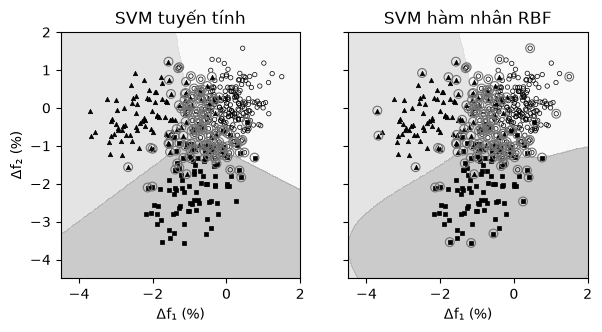

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(6.8, 3.2), sharey=True)
for ax, nhan in zip(axs, ["linear", "rbf"]):
    sv = make_pipeline(StandardScaler(),
                       SVC(kernel=nhan, C=1, gamma=0.5))
    sv.fit(X2_tr, y2_tr)
    ve_bien(ax, sv, *lim, vien=False)
    ve_diem(ax, X2_tr, y2_tr)
    vt = X2_tr[sv[-1].support_]  # cac vecto ho tro
    ax.scatter(vt[:, 0], vt[:, 1], s=40, facecolors="none",
               edgecolors="0.45", linewidths=0.8)
    ax.set_title("SVM tuyến tính" if nhan == "linear"
                 else "SVM hàm nhân RBF")
    ax.set_xlabel("Δf₁ (%)")
axs[0].set_ylabel("Δf₂ (%)")
plt.show()

### So sánh các thuật toán

In [14]:
mo_hinh = {
    "Logistic": make_pipeline(StandardScaler(),
                              LogisticRegression()),
    "kNN (k=15)": make_pipeline(StandardScaler(),
                                KNeighborsClassifier(15)),
    "Bayes don gian": GaussianNB(),
    "Cay cat tia": cay,
    "Rung ngau nhien": rf,
    "SVM RBF": make_pipeline(StandardScaler(),
                             SVC(C=1, gamma=0.5)),
}
for ten, mh in mo_hinh.items():
    mh.fit(X2_tr, y2_tr)
    print(f"{ten:16s}: kiem tra {mh.score(X2_te, y2_te):.3f}")

Logistic        : kiem tra 0.906
kNN (k=15)      : kiem tra 0.911
Bayes don gian  : kiem tra 0.906
Cay cat tia     : kiem tra 0.906


Rung ngau nhien : kiem tra 0.911
SVM RBF         : kiem tra 0.906


## ỨNG DỤNG: NHẬN DẠNG HƯ HỎNG VÀ PHÂN LOẠI TÌNH TRẠNG KỸ THUẬT

### Nhận dạng hư hỏng từ đặc trưng dao động

In [15]:
rng = np.random.default_rng(2024)
f0 = np.array([3.20, 12.60, 28.00])  # tan so o 20 do C (Hz)
a_T = np.array([-0.0020, -0.0015, -0.0025])  # 1/do C
giam = {0: [0.0, 0.0, 0.0],    # NV
        1: [-2.4, -0.2, -2.0], # GN, giam tan so (%)
        2: [-1.2, -2.6, -1.0]} # PN, giam tan so (%)
so_mau = {0: 400, 1: 100, 2: 100}
hang = []
for lop, so in so_mau.items():
    T = rng.uniform(10, 40, so)  # nhiet do ket cau (do C)
    muc = rng.uniform(0.6, 1.4, so) if lop else np.zeros(so)
    for i in range(so):
        h = 1 + np.array(giam[lop]) * muc[i] / 100
        f = f0 * h * (1 + a_T * (T[i] - 20))
        f = f * (1 + rng.normal(0, 0.003, 3))
        hang.append([*f, T[i], lop])
dd = pd.DataFrame(hang, columns=["f1", "f2", "f3", "T", "lop"])
print("Tan so trung binh (Hz) theo lop:")
print(dd.groupby("lop")[["f1", "f2", "f3"]].mean().round(3))
print("Bien thien f1 khi T tu 10 den 40 do C:",
      round(f0[0] * 0.002 * 30, 3), "Hz")

Tan so trung binh (Hz) theo lop:
        f1      f2      f3
lop                       
0    3.173  12.520  27.715
1    3.094  12.472  27.108
2    3.133  12.189  27.396
Bien thien f1 khi T tu 10 den 40 do C: 0.192 Hz


In [16]:
from sklearn.metrics import ConfusionMatrixDisplay

y3 = dd["lop"].to_numpy()
kq = {}
tap_bien = [["f1"], ["f1", "f2", "f3"], ["f1", "f2", "f3", "T"]]
for bien in tap_bien:
    X3 = dd[bien].to_numpy()
    X3_tr, X3_te, y3_tr, y3_te = train_test_split(
        X3, y3, test_size=0.3, stratify=y3, random_state=3)
    for ten, mh in [
            ("RF", RandomForestClassifier(300, random_state=0)),
            ("SVM", make_pipeline(StandardScaler(),
                                  SVC(C=10)))]:
        mh.fit(X3_tr, y3_tr)
        kq[ten, len(bien)] = mh.predict(X3_te)
        print(f"{ten:3s}, {'+'.join(bien):11s}: kiem tra "
              f"{mh.score(X3_te, y3_te):.3f}")

RF , f1         : kiem tra 0.600
SVM, f1         : kiem tra 0.744


RF , f1+f2+f3   : kiem tra 0.917
SVM, f1+f2+f3   : kiem tra 0.939


RF , f1+f2+f3+T : kiem tra 0.972
SVM, f1+f2+f3+T : kiem tra 0.994


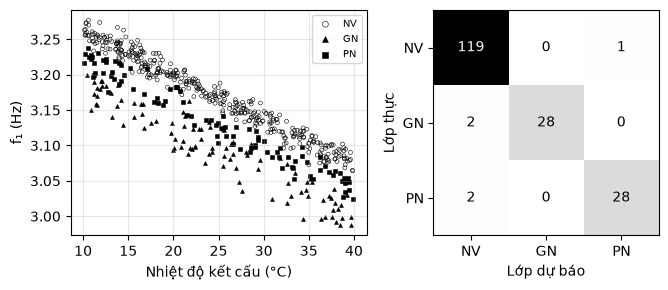

In [17]:
ten_lop = ["NV", "GN", "PN"]
fig, axs = plt.subplots(1, 2, figsize=(6.8, 3.0),
                        gridspec_kw={"width_ratios": [1.3, 1]})
for lop, mk in [(0, "o"), (1, "^"), (2, "s")]:
    m = dd["lop"] == lop
    axs[0].scatter(dd.loc[m, "T"], dd.loc[m, "f1"], marker=mk,
                   s=8, facecolors="none" if lop == 0 else "k",
                   edgecolors="k", linewidths=0.4,
                   label=ten_lop[lop])
axs[0].set_xlabel("Nhiệt độ kết cấu (°C)")
axs[0].set_ylabel("f₁ (Hz)")
axs[0].legend(fontsize=7, markerscale=1.5)
axs[0].grid(alpha=0.3)
ConfusionMatrixDisplay.from_predictions(
    y3_te, kq["RF", 4], display_labels=ten_lop, cmap="Greys",
    colorbar=False, ax=axs[1])
axs[1].set_xlabel("Lớp dự báo")
axs[1].set_ylabel("Lớp thực")
fig.tight_layout()
plt.show()

### Phân loại tình trạng kỹ thuật cầu từ dữ liệu kiểm tra

In [18]:
rng = np.random.default_rng(31)
n = 300
loai = rng.choice(["BTCT", "DUL", "Thep", "LienHop"], n,
                  p=[0.30, 0.35, 0.15, 0.20])
cau = pd.DataFrame({
    "tuoi": rng.uniform(3, 60, n).round(0),         # nam
    "nhip": rng.uniform(15, 60, n).round(1),        # m
    "loai": loai,
    "xe_tai": rng.lognormal(7.0, 0.7, n).round(0),  # xe/ngd
    "kc_bien": rng.uniform(0.5, 80, n).round(1),    # km
})
he_so = {"BTCT": 0.4, "DUL": 0.0, "Thep": 0.6, "LienHop": 0.3}
s = (0.045 * cau["tuoi"] + 0.5 * np.log(cau["xe_tai"] / 1000)
     + 1.2 * np.exp(-cau["kc_bien"] / 15)
     + cau["loai"].map(he_so) + rng.normal(0, 0.35, n))
cau["cap"] = np.digitize(s, [1.0, 1.9, 2.7]) + 1
print(cau.head(4))
print("So cau theo cap:",
      cau["cap"].value_counts().sort_index().to_dict())

   tuoi  nhip     loai  xe_tai  kc_bien  cap
0  25.0  48.8  LienHop   260.0     65.0    1
1  41.0  35.3     BTCT   557.0     48.8    2
2   9.0  55.8     Thep   412.0     22.1    2
3  37.0  54.9      DUL  1181.0     11.2    2
So cau theo cap: {1: 64, 2: 100, 3: 70, 4: 66}


In [19]:
Xc = pd.get_dummies(cau.drop(columns="cap"),
                    columns=["loai"], dtype=int)
yc = cau["cap"].to_numpy()
print("Cac cot dac trung:", list(Xc.columns))
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(
    Xc, yc, test_size=0.3, stratify=yc, random_state=5)
rf_c = RandomForestClassifier(n_estimators=400,
                              min_samples_leaf=2,
                              oob_score=True, random_state=0)
rf_c.fit(Xc_tr, yc_tr)
yc_du = rf_c.predict(Xc_te)
print("oob =", round(rf_c.oob_score_, 3), "| kiem tra =",
      round(accuracy_score(yc_te, yc_du), 3))
sai = yc_du != yc_te
lech1 = np.abs(yc_du - yc_te) == 1
print("So cau sai:", sai.sum(),
      "| sai lech 1 cap:", lech1.sum())

Cac cot dac trung: ['tuoi', 'nhip', 'xe_tai', 'kc_bien', 'loai_BTCT', 'loai_DUL', 'loai_LienHop', 'loai_Thep']


oob = 0.614 | kiem tra = 0.656
So cau sai: 31 | sai lech 1 cap: 30


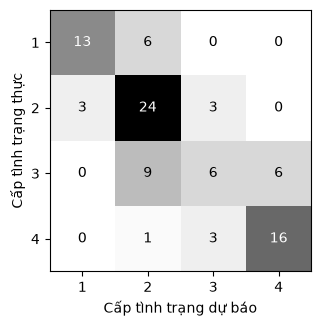

In [20]:
fig, ax = plt.subplots(figsize=(4.0, 3.4))
ConfusionMatrixDisplay.from_predictions(
    yc_te, yc_du, cmap="Greys", colorbar=False, ax=ax)
ax.set_xlabel("Cấp tình trạng dự báo")
ax.set_ylabel("Cấp tình trạng thực")
plt.show()

## BÀI TẬP